In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## confidence-histogram

**Figure 1: Distribution of the model's confidence on correct and incorrect answers.** Dashed lines mark each group's mean confidence; densities are normalized per group (1,800 correct, 420 incorrect answers). Correct answers concentrate at high confidence (mean 0.834), while incorrect ones spread across the range (mean 0.575), so confidence separates the two.

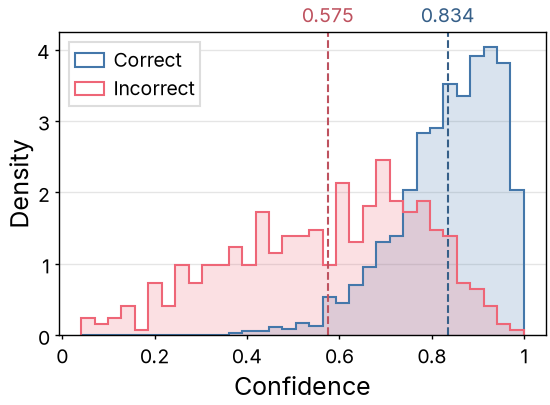

In [2]:
with open("../data/confidence-histogram.json") as f:
    data = json.load(f)

fig, ax = plt.subplots(figsize=(2.75, 2))
bins = np.histogram_bin_edges(np.concatenate([data["correct"], data["incorrect"]]), bins="auto")
for name, values, color in [
    ("Correct", data["correct"], colors["series-1"]),
    ("Incorrect", data["incorrect"], colors["series-2"]),
]:
    ax.hist(values, bins=bins, density=True, histtype="stepfilled", color=color, alpha=0.2, linewidth=0)
    ax.hist(values, bins=bins, density=True, histtype="step", color=color, label=name)
    mean = np.mean(values)
    ax.axvline(mean, linestyle="--", linewidth=paper.dashed_width, color=darken(color))
    ax.annotate(f"{mean:#.3g}", (mean, 1), xycoords=("data", "axes fraction"), xytext=(0, 2),
                textcoords="offset points", ha="center", va="bottom", color=darken(color))

ax.grid(axis="x", visible=False)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:g}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}")
ax.set_xlabel("Confidence")
ax.set_ylabel("Density")
ax.legend(loc="upper left")

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/confidence-histogram.pdf")
fig.savefig("../outputs/confidence-histogram.png")
plt.show()